# DATA 266 · HW11 · Part 1 — LLM optimisation with GPTQ

**Student:** Ritika Mukesh Neema · SID4 6638

This notebook quantizes a base causal LM to 4-bit with GPTQ and compares the **unquantized (FP16)** and **GPTQ (INT4)** versions of the *same* model on:

| Metric | How it is measured |
|---|---|
| Quality | Wikitext-2 (`Salesforce/wikitext`, `wikitext-2-raw-v1`) **test** perplexity and eval loss, non-overlapping windows |
| Latency | p50 / p95 over repeated runs, batch 1, same GPU: (a) prefill = one forward pass over a fixed-length prompt, (b) generation = fixed number of new tokens, greedy |
| Memory | Peak GPU memory (`torch.cuda.max_memory_allocated`) during load + evaluation + latency runs, plus weights-only memory after load |
| Size | On-disk size of the saved model folder (`save_pretrained`, safetensors) |

Wikitext-2 is used only for calibration (**train** split) and evaluation (**test** split). The base model ID and revision are pinned and identical for both runs.

**Runtime:** Colab → *Runtime → Change runtime type → T4 GPU*.

## Install

GPTQ in Transformers now uses the **GPT-QModel** backend (`gptqmodel`); AutoGPTQ is no longer supported. `gptqmodel` needs a recent PyTorch, so pip may upgrade torch. The cell below installs once and then **restarts the runtime automatically** (Colab shows a "session crashed" notice; that is expected). After the restart, run all cells again; the install cell will skip itself.

In [1]:
import os
FLAG = "/content/.hw11_part1_deps_ok" if os.path.isdir("/content") else ".hw11_part1_deps_ok"
if not os.path.exists(FLAG):
    !pip install -q -U accelerate optimum transformers datasets
    !pip install -q gptqmodel --no-build-isolation
    open(FLAG, "w").write("ok")
    print("Installed. Restarting runtime; re-run all cells afterwards.")
    os.kill(os.getpid(), 9)
else:
    print("Dependencies already installed.")

Dependencies already installed.


## Step 0 — SID-derived parameters (same as Assignment 1)

In [2]:
import os, gc, json, time, random, platform
import numpy as np
import torch

SID4  = 6638
SEED  = 6638          # SID4
SLICE = 638           # SID4 % 1000
HP_ID = 2             # SID4 % 6
CLS_A = 8             # SID4 % 10
CLS_B = 5             # (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seeds()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figs", exist_ok=True); os.makedirs("artifacts", exist_ok=True)

RUN_LOG = []
def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line); RUN_LOG.append(line)

import transformers, importlib.metadata as md_
def _v(p):
    try: return md_.version(p)
    except Exception: return "n/a"
log(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
log(f"python={platform.python_version()} torch={torch.__version__} transformers={transformers.__version__} "
    f"gptqmodel={_v('gptqmodel')} optimum={_v('optimum')} datasets={_v('datasets')}")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
log(f"device={DEVICE} ({GPU_NAME})")

[21:18:02] SID4=6638 SEED=6638 SLICE=638 HP_ID=2 CLS_A=8 CLS_B=5
[21:18:02] python=3.13.16 torch=2.15.0+cu132 transformers=5.24.1 gptqmodel=7.12.2 optimum=2.3.0 datasets=5.2.0
[21:18:02] device=cuda (NVIDIA L4)


## Configuration

`MODEL_ID` is the base LLM. `facebook/opt-125m` is the model used in the Hugging Face GPTQ guide; **if the instructor provided or approved a different model, change it here** — everything else adapts. The exact Hub commit (revision SHA) is resolved and pinned below, and both runs load that same revision.

In [4]:
MODEL_ID     = "facebook/opt-125m"   # instructor-provided / approved base LLM
BITS         = 4
GROUP_SIZE   = 128
N_CALIB      = 128                   # calibration samples from Wikitext-2 TRAIN
CALIB_TOKENS = 512                   # tokens per calibration sample
EVAL_SEQLEN  = 2048                  # perplexity window (capped at the model's max context)

# Latency protocol (identical for both models, batch size 1)
N_WARMUP        = 5
N_RUNS          = 50
PROMPT_TOKENS   = 128                # generation prompt length
NEW_TOKENS      = 64                 # forced generation length (greedy)
PREFILL_TOKENS  = 512                # single forward-pass length
N_PROMPTS       = 20                 # distinct prompts, cycled across runs

BASE_DIR = "artifacts/base_fp16"
GPTQ_DIR = "artifacts/gptq_int4"

## Pin the model revision and load Wikitext-2

In [5]:
from huggingface_hub import HfApi
from transformers import AutoTokenizer
from datasets import load_dataset

try:
    REVISION = HfApi().model_info(MODEL_ID).sha
except Exception as e:
    REVISION = "main"; log(f"WARNING: could not resolve revision SHA ({e}); using 'main'")
log(f"MODEL_ID={MODEL_ID}  REVISION={REVISION}")

tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

wt = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
log(f"wikitext-2-raw-v1: " + ", ".join(f"{k}={len(v)} rows" for k, v in wt.items()))

# Test split -> one long token stream (standard GPTQ-paper protocol)
test_ids = tok("\n\n".join(wt["test"]["text"]), return_tensors="pt").input_ids
train_ids = tok("\n\n".join(wt["train"]["text"]), return_tensors="pt").input_ids
log(f"test tokens={test_ids.numel():,}  train tokens={train_ids.numel():,}")

[21:18:09] MODEL_ID=facebook/opt-125m  REVISION=27dcfa74d334bc871f3234de431e71c6eeba5dd6
[21:18:13] wikitext-2-raw-v1: test=4358 rows, train=36718 rows, validation=3760 rows
[21:18:27] test tokens=287,645  train tokens=2,428,602


## Shared measurement helpers

The same functions measure both models. Perplexity uses non-overlapping windows of `EVAL_SEQLEN` tokens over the whole test stream; loss is the token-weighted mean NLL. Latency is wall-clock with `torch.cuda.synchronize()` around each run.

In [6]:
from transformers import AutoModelForCausalLM

def model_max_len(model):
    return getattr(model.config, "max_position_embeddings", EVAL_SEQLEN)

@torch.no_grad()
def wikitext_perplexity(model, ids=None):
    ids = test_ids if ids is None else ids
    seqlen = min(EVAL_SEQLEN, model_max_len(model))
    n_win = ids.size(1) // seqlen
    nll_sum, n_tok = 0.0, 0
    for i in range(n_win):
        x = ids[:, i * seqlen:(i + 1) * seqlen].to(model.device)
        out = model(x, labels=x)
        n = x.size(1) - 1                     # tokens actually predicted in this window
        nll_sum += out.loss.float().item() * n
        n_tok += n
    loss = nll_sum / n_tok
    return {"eval_loss": loss, "perplexity": float(np.exp(loss)), "windows": n_win, "seqlen": seqlen, "tokens_scored": n_tok}

# Fixed prompts (same for both models), drawn from the TEST stream with SEED
_rng = np.random.default_rng(SEED)
_starts = _rng.integers(0, test_ids.size(1) - max(PROMPT_TOKENS, PREFILL_TOKENS) - 1, size=N_PROMPTS)
GEN_PROMPTS     = [test_ids[:, s:s + PROMPT_TOKENS] for s in _starts]
PREFILL_PROMPTS = [test_ids[:, s:s + PREFILL_TOKENS] for s in _starts]

def _sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

@torch.no_grad()
def latency(model, mode):
    prompts = GEN_PROMPTS if mode == "generate" else PREFILL_PROMPTS
    def run(x):
        x = x.to(model.device)
        if mode == "generate":
            model.generate(x, attention_mask=torch.ones_like(x), max_new_tokens=NEW_TOKENS,
                           min_new_tokens=NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
        else:
            model(x)
    for i in range(N_WARMUP):
        run(prompts[i % len(prompts)])
    times = []
    for i in range(N_RUNS):
        _sync(); t0 = time.perf_counter()
        run(prompts[i % len(prompts)])
        _sync(); times.append((time.perf_counter() - t0) * 1000)
    t = np.array(times)
    return {"p50_ms": float(np.percentile(t, 50)), "p95_ms": float(np.percentile(t, 95)),
            "mean_ms": float(t.mean()), "runs": N_RUNS, "all_ms": t.tolist()}

def dir_size_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 2**20

def free():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def measure(name, load_fn, save_dir):
    # Clean slate, then: load -> perplexity -> latency; peak memory covers the whole sequence.
    free()
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    model = load_fn(); model.eval()
    weights_mb = torch.cuda.memory_allocated() / 2**20 if torch.cuda.is_available() else float("nan")
    try:
        qlin = type(model.get_decoder().layers[0].self_attn.q_proj).__name__
    except Exception:
        qlin = "?"
    log(f"[{name}] loaded; weights on GPU = {weights_mb:.1f} MiB; q_proj layer type = {qlin}")

    t0 = time.perf_counter(); ppl = wikitext_perplexity(model); t_ppl = time.perf_counter() - t0
    log(f"[{name}] Wikitext-2 test: loss={ppl['eval_loss']:.4f}  ppl={ppl['perplexity']:.3f}  "
        f"({ppl['windows']} x {ppl['seqlen']} tokens, {t_ppl:.1f}s)")
    lat_pre = latency(model, "prefill")
    log(f"[{name}] prefill {PREFILL_TOKENS} tok: p50={lat_pre['p50_ms']:.2f} ms  p95={lat_pre['p95_ms']:.2f} ms")
    lat_gen = latency(model, "generate")
    log(f"[{name}] generate {PROMPT_TOKENS}->+{NEW_TOKENS} tok: p50={lat_gen['p50_ms']:.1f} ms  p95={lat_gen['p95_ms']:.1f} ms")
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else float("nan")
    disk_mb = dir_size_mb(save_dir)
    log(f"[{name}] peak GPU memory = {peak_mb:.1f} MiB; on-disk = {disk_mb:.1f} MiB")
    rec = {"name": name, "layer_type": qlin, "weights_gpu_mib": weights_mb, "peak_gpu_mib": peak_mb,
           "disk_mib": disk_mb, "ppl_eval_seconds": t_ppl, **{f"wikitext_{k}": v for k, v in ppl.items()},
           "prefill": lat_pre, "generate": lat_gen}
    del model; free()
    return rec

## 1 · Base model (unquantized, FP16)

The base checkpoint is loaded in FP16 (the usual serving precision and the precision GPTQ's activations run in) and saved locally so on-disk size is measured the same way for both models.

In [7]:
set_seeds()
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, dtype=torch.float16).to(DEVICE)
n_params = sum(p.numel() for p in base.parameters())
log(f"base params = {n_params/1e6:.1f}M")
base.save_pretrained(BASE_DIR); tok.save_pretrained(BASE_DIR)
del base; free()

base_rec = measure("base_fp16",
                   lambda: AutoModelForCausalLM.from_pretrained(BASE_DIR, dtype=torch.float16).to(DEVICE),
                   BASE_DIR)
base_rec["params_m"] = n_params / 1e6

W1124 21:18:29.940000 6228 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 21:18:29.994000 6228 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

[21:18:36] base params = 125.2M


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  251MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[21:18:37] [base_fp16] loaded; weights on GPU = 245.5 MiB; q_proj layer type = Linear
[21:18:40] [base_fp16] Wikitext-2 test: loss=3.3198  ppl=27.656  (140 x 2048 tokens, 3.2s)
[21:18:41] [base_fp16] prefill 512 tok: p50=10.14 ms  p95=11.05 ms
[21:19:15] [base_fp16] generate 128->+64 tok: p50=617.9 ms  p95=641.4 ms
[21:19:15] [base_fp16] peak GPU memory = 1570.8 MiB; on-disk = 242.3 MiB


## 2 · Quantize with GPTQ

Calibration data: `N_CALIB` random windows of `CALIB_TOKENS` tokens from the Wikitext-2 **train** split (seeded with `SEED`), passed to `GPTQConfig` as a list of strings. Settings: 4-bit, group size 128, symmetric, `desc_act=False` (the GPTQ defaults in Transformers).

In [8]:
from transformers import GPTQConfig

rng = np.random.default_rng(SEED)
starts = rng.integers(0, train_ids.size(1) - CALIB_TOKENS - 1, size=N_CALIB)
calib_texts = [tok.decode(train_ids[0, s:s + CALIB_TOKENS]) for s in starts]
log(f"calibration: {len(calib_texts)} samples x {CALIB_TOKENS} tokens from wikitext-2 train")

gptq_cfg = GPTQConfig(bits=BITS, group_size=GROUP_SIZE, dataset=calib_texts, tokenizer=tok,
                      desc_act=False, sym=True)

free()
t0 = time.perf_counter()
qmodel = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, dtype=torch.float16,
                                              device_map=DEVICE, quantization_config=gptq_cfg)
QUANT_SECONDS = time.perf_counter() - t0
log(f"GPTQ quantization finished in {QUANT_SECONDS:.1f}s")
qmodel.save_pretrained(GPTQ_DIR); tok.save_pretrained(GPTQ_DIR)
del qmodel; free()

[21:19:15] calibration: 128 samples x 512 tokens from wikitext-2 train

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.12.2 Transformers : 5.24.1 Torch        : 2.15.0+cu132 Triton       : 3.9.0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Quantizing model.decoder.layers blocks :   0%|          | 0/12 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

INFO  GPTQ block update: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/gptq_block/328413dd8682e7d3`.
INFO  GPTQ block update: torch.ops JIT extension ready in 33s.                  


Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

... (10 outputs left out)

INFO  ExLlamaV2 GPTQ: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/exllamav2/efa349091c18df73`.
INFO  ExLlamaV2 GPTQ: torch.ops JIT extension ready in 55s (estimated ~35s, +21s).
INFO  Packing Kernel: Auto-selection: adding candidate `TritonV2Linear`         
INFO  Kernel: selected -> `TritonV2Linear`.                                     


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3312: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


INFO  Optimize: `TritonV2Linear` compilation triggered.                         
INFO  gc.collect() reclaimed 208 objects in 0.359s                              
[21:21:02] GPTQ quantization finished in 106.6s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 3 · Reload the GPTQ model from disk and measure it the same way

In [9]:
gptq_rec = measure("gptq_int4",
                   lambda: AutoModelForCausalLM.from_pretrained(GPTQ_DIR, device_map=DEVICE),
                   GPTQ_DIR)
gptq_rec["quantization_seconds"] = QUANT_SECONDS
gptq_rec["params_m"] = base_rec["params_m"]

INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: backend.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: batch_size.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: block_name_to_quantize.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: cache_block_outputs.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: dataset.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: max_input_length.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: model_seqlen.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: module_name_preceding_first_block.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: pad_token_id.
INFO  QuantizeConfig: Ignoring unknown parameter in the quantization configuration: toke

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

[transformers] OPTForCausalLM LOAD REPORT from: artifacts/gptq_int4
Key                                                            | Status  | 
---------------------------------------------------------------+---------+-
model.decoder.layers.{0...11}.self_attn.q_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.self_attn.out_proj.qzeros_format | MISSING | 
model.decoder.layers.{0...11}.fc1.qzeros_format                | MISSING | 
model.decoder.layers.{0...11}.self_attn.k_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.self_attn.v_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.fc2.qzeros_format                | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


INFO  Marlin fp16: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/marlin_fp16/cc1fef1dac570956`.
INFO  Marlin fp16: torch.ops JIT extension ready in 166s (estimated ~117s, +49s).
INFO  gc.collect() reclaimed 4087 objects in 0.361s                             
[21:23:53] [gptq_int4] loaded; weights on GPU = 118.7 MiB; q_proj layer type = MarlinLinear
[21:23:57] [gptq_int4] Wikitext-2 test: loss=3.4293  ppl=30.855  (140 x 2048 tokens, 4.0s)
[21:23:59] [gptq_int4] prefill 512 tok: p50=20.23 ms  p95=20.85 ms
[21:25:07] [gptq_int4] generate 128->+64 tok: p50=1240.8 ms  p95=1281.4 ms
[21:25:07] [gptq_int4] peak GPU memory = 1444.0 MiB; on-disk = 123.0 MiB


## 4 · Results

In [10]:
import pandas as pd

def row(r):
    return {"Model": r["name"],
            "Wikitext-2 loss": round(r["wikitext_eval_loss"], 4),
            "Perplexity": round(r["wikitext_perplexity"], 3),
            "Prefill p50 (ms)": round(r["prefill"]["p50_ms"], 2),
            "Prefill p95 (ms)": round(r["prefill"]["p95_ms"], 2),
            "Generate p50 (ms)": round(r["generate"]["p50_ms"], 1),
            "Generate p95 (ms)": round(r["generate"]["p95_ms"], 1),
            "Weights on GPU (MiB)": round(r["weights_gpu_mib"], 1),
            "Peak GPU mem (MiB)": round(r["peak_gpu_mib"], 1),
            "On-disk (MiB)": round(r["disk_mib"], 1),
            "Linear layer": r["layer_type"]}

results = pd.DataFrame([row(base_rec), row(gptq_rec)]).set_index("Model")
display(results.T)

def ratio(k1, k2=None):
    g = gptq_rec[k1] if k2 is None else gptq_rec[k1][k2]
    b = base_rec[k1] if k2 is None else base_rec[k1][k2]
    return g / b
summary = {
    "perplexity_change_pct": 100 * (gptq_rec["wikitext_perplexity"] / base_rec["wikitext_perplexity"] - 1),
    "prefill_p50_ratio_gptq_over_base": ratio("prefill", "p50_ms"),
    "generate_p50_ratio_gptq_over_base": ratio("generate", "p50_ms"),
    "generate_p95_ratio_gptq_over_base": ratio("generate", "p95_ms"),
    "peak_mem_ratio_gptq_over_base": ratio("peak_gpu_mib"),
    "weights_mem_ratio_gptq_over_base": ratio("weights_gpu_mib"),
    "disk_ratio_gptq_over_base": ratio("disk_mib"),
}
for k, v in summary.items(): log(f"{k} = {v:.3f}")

Model,base_fp16,gptq_int4
Wikitext-2 loss,3.3198,3.4293
Perplexity,27.656,30.855
Prefill p50 (ms),10.14,20.23
Prefill p95 (ms),11.05,20.85
Generate p50 (ms),617.9,1240.8
Generate p95 (ms),641.4,1281.4
Weights on GPU (MiB),245.5,118.7
Peak GPU mem (MiB),1570.8,1444.0
On-disk (MiB),242.3,123.0
Linear layer,Linear,MarlinLinear


[21:25:08] perplexity_change_pct = 11.568
[21:25:08] prefill_p50_ratio_gptq_over_base = 1.994
[21:25:08] generate_p50_ratio_gptq_over_base = 2.008
[21:25:08] generate_p95_ratio_gptq_over_base = 1.998
[21:25:08] peak_mem_ratio_gptq_over_base = 0.919
[21:25:08] weights_mem_ratio_gptq_over_base = 0.484
[21:25:08] disk_ratio_gptq_over_base = 0.508


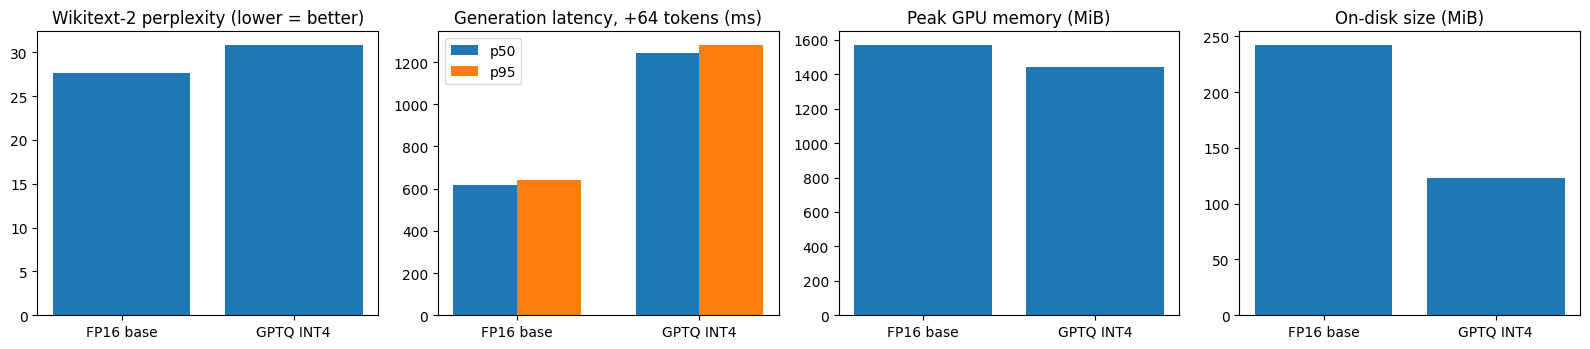

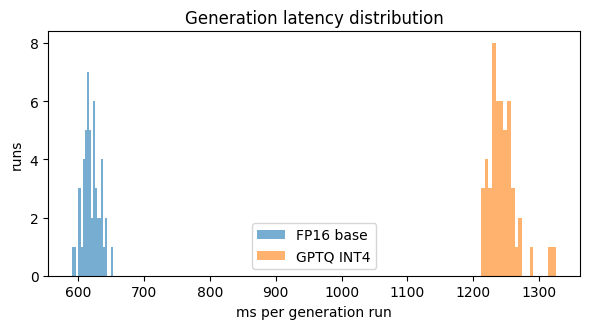

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
names = ["FP16 base", "GPTQ INT4"]
recs = [base_rec, gptq_rec]
ax[0].bar(names, [r["wikitext_perplexity"] for r in recs]); ax[0].set_title("Wikitext-2 perplexity (lower = better)")
w = 0.35; x = np.arange(2)
ax[1].bar(x - w/2, [r["generate"]["p50_ms"] for r in recs], w, label="p50")
ax[1].bar(x + w/2, [r["generate"]["p95_ms"] for r in recs], w, label="p95")
ax[1].set_xticks(x, names); ax[1].set_title(f"Generation latency, +{NEW_TOKENS} tokens (ms)"); ax[1].legend()
ax[2].bar(names, [r["peak_gpu_mib"] for r in recs]); ax[2].set_title("Peak GPU memory (MiB)")
ax[3].bar(names, [r["disk_mib"] for r in recs]); ax[3].set_title("On-disk size (MiB)")
plt.tight_layout(); plt.savefig("figs/part1_gptq_comparison.png", dpi=150); plt.show()

plt.figure(figsize=(6, 3.4))
plt.hist(base_rec["generate"]["all_ms"], bins=20, alpha=.6, label="FP16 base")
plt.hist(gptq_rec["generate"]["all_ms"], bins=20, alpha=.6, label="GPTQ INT4")
plt.xlabel("ms per generation run"); plt.ylabel("runs"); plt.legend(); plt.title("Generation latency distribution")
plt.tight_layout(); plt.savefig("figs/part1_latency_hist.png", dpi=150); plt.show()

In [12]:
part1 = {"model_id": MODEL_ID, "revision": REVISION, "gpu": GPU_NAME,
         "gptq": {"bits": BITS, "group_size": GROUP_SIZE, "n_calib": N_CALIB, "calib_tokens": CALIB_TOKENS,
                  "calib_split": "wikitext-2-raw-v1/train", "desc_act": False, "sym": True},
         "eval": {"split": "wikitext-2-raw-v1/test", "seqlen": base_rec["wikitext_seqlen"]},
         "latency_protocol": {"batch": 1, "warmup": N_WARMUP, "runs": N_RUNS, "prompt_tokens": PROMPT_TOKENS,
                              "new_tokens": NEW_TOKENS, "prefill_tokens": PREFILL_TOKENS},
         "base": {k: v for k, v in base_rec.items()}, "gptq_model": {k: v for k, v in gptq_rec.items()},
         "summary": summary}
for r in (part1["base"], part1["gptq_model"]):
    r["prefill"] = {k: v for k, v in r["prefill"].items() if k != "all_ms"}
    r["generate"] = {k: v for k, v in r["generate"].items() if k != "all_ms"}
json.dump(part1, open("part1_metrics.json", "w"), indent=2)
open("RUN_LOG_part1.txt", "w").write("\n".join(RUN_LOG) + "\n")
print("saved part1_metrics.json, RUN_LOG_part1.txt, figs/part1_*.png")

saved part1_metrics.json, RUN_LOG_part1.txt, figs/part1_*.png


## 5 · Findings

**Setup.** `facebook/opt-125m` at revision `27dcfa74d334bc871f3234de431e71c6eeba5dd6`, both models on the same NVIDIA L4 GPU. GPTQ settings: 4-bit, group size 128, 128 × 512-token calibration windows from Wikitext-2 *train*. Both models were evaluated on the full Wikitext-2 *test* stream (140 windows × 2,048 tokens).

| | FP16 base | GPTQ INT4 | GPTQ / base |
|---|---|---|---|
| Wikitext-2 eval loss | 3.3198 | 3.4293 | +0.110 nats |
| Perplexity | 27.66 | 30.86 | +11.6% |
| Prefill p50 / p95, 512 tok (ms) | 10.14 / 11.05 | 20.23 / 20.85 | 2.0× slower |
| Generate p50 / p95, +64 tok (ms) | 617.9 / 641.4 | 1240.8 / 1281.4 | 2.0× slower |
| Weights on GPU (MiB) | 245.5 | 118.7 | 0.48 |
| Peak GPU memory (MiB) | 1570.8 | 1444.0 | 0.92 |
| On-disk size (MiB) | 242.3 | 123.0 | 0.51 |

- **Quality.** 4-bit GPTQ raised perplexity from 27.66 to 30.86 (+11.6%), which is +0.11 nats of loss per token. The FP16 perplexity matches the figure reported for OPT-125M in the GPTQ paper (≈27.65), and the INT4 result is close to the paper's 4-bit GPTQ number (≈31). The pipeline therefore behaves as expected. The cost is noticeable because a 125M-parameter model has little redundancy to absorb rounding error. Larger models usually lose far less at 4 bits.
- **Latency.** GPTQ was about 2× *slower* for both prefill and generation. p95 was within about 4% of p50 for both models, so the gap is consistent, not noise. At batch size 1, a 125M model is not limited by memory bandwidth. Each decode step (about 9.7 ms/token for FP16) is dominated by kernel-launch and Python overhead across 12 layers. The INT4 Marlin kernels add dequantisation work and extra launches per linear layer, and they save little because reading the weights was never the bottleneck. The speed advantage of 4-bit weights appears on multi-billion-parameter models, where decode time is mostly time spent reading weights.
- **Memory.** Weight memory roughly halved (245.5 → 118.7 MiB), but peak memory fell only 8% (1571 → 1444 MiB). The peak comes from activations during the 2,048-token evaluation, mainly the 2,048 × 50,272 logits tensor. Weights are only a small part of it.
- **Disk.** The saved model shrank by 49% (242 → 123 MiB), not the roughly 75% that 16 → 4 bits would suggest. GPTQ quantizes only the decoder's linear layers. The token and position embeddings (about 40M of the 125M parameters, with the token embedding shared with the output layer) stay in FP16, and each 128-weight group also stores a scale and zero-point.
- **Takeaway.** On this small model, GPTQ halves weight memory and storage for an 11.6% perplexity increase, with no latency benefit on this hardware. It is most useful when a model is memory-bound or does not fit in GPU memory, which describes larger LLMs rather than OPT-125M.
- **Note.** The load report lists `qzeros_format` as MISSING. This is a GPT-QModel format flag, not a weight tensor. The perplexity after reloading from disk matches the expected 4-bit result, so the quantized weights loaded correctly.
